# PPO con política gaussiana para MPPT bajo sombreado parcial

Agente **PPO (Proximal Policy Optimization)** entrenado sobre el entorno `PVMPPTEnv`.

**Diseño**

* **Política gaussiana**: la red de actor produce la media `mu(s)` y hay un `log_std` independiente del estado.
  La acción muestreada es `u ~ N(mu(s), sigma)`. Como el entorno en modo `absolute` acepta `a ∈ [0, 1]`,
  se recorta `a = clip(u, 0, 1)` solo al enviarla al entorno; la verosimilitud del PPO se calcula sobre `u`
  (sin recortar), que es lo correcto para el gradiente.
* **Crítico** `V(s)` separado, con **GAE** (λ = 0.95) y el objetivo **clipped** de PPO (ε = 0.2).
* **Truncamiento**: el episodio termina por `max_steps`, no por un estado terminal. En ese caso se
  suma `γ·V(s_final)` a la recompensa (bootstrap), en lugar de tratarlo como fin real.
* El agente **no observa la sombra** directamente: solo ve `[I, V, P, dI, dP]` normalizados, igual que en el entorno.

**Evaluación**: política determinista (`mu`) sobre las 12 combinaciones de la Fig. 14 del paper, comparada
con la línea base `scan_and_hold`.

## 1. Entorno

In [2]:
from __future__ import annotations

from pathlib import Path
from typing import Optional, Sequence, Union

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from gymnasium import spaces

CaseLike = Union[str, Path, np.ndarray]

In [3]:
class PVCurve:
    """Curva I-V de un patron de sombreado, invertida como V(I) por interpolacion."""

    def __init__(self, data: np.ndarray, name: str = "caso"):
        data = np.asarray(data, dtype=np.float64)
        if data.ndim != 2 or data.shape[1] != 3:
            raise ValueError(f"'{name}': se esperaba forma (N, 3) = [I, V, P], llego {data.shape}")
        i, v, _ = data.T  # la P del archivo no se usa: se recalcula como I*V

        # Los datos vienen ordenados por V creciente (I decreciente). En casos con
        # sombra hay pequenas no-monotonias numericas (~1e-5 A) que se eliminan
        # para poder invertir la curva: I(V) -> V(I).
        i = np.minimum.accumulate(i)
        i, v = i[::-1], v[::-1]
        self.i, inv = np.unique(i, return_inverse=True)  # I ascendente, sin repetidos
        self.v = np.bincount(inv.ravel(), weights=v) / np.bincount(inv.ravel())

        self.name = name
        self.isc = float(self.i[-1])  # corriente de corto circuito del caso
        self.voc = float(self.v.max())

        # GMPP sobre la curva interpolada (consistente con el modelo del entorno)
        dense = np.linspace(0.0, self.isc, 200_001)
        p = dense * np.interp(dense, self.i, self.v)
        self.p_gmpp = float(p.max())
        self.i_gmpp = float(dense[p.argmax()])

    def operating_point(self, i_cmd: float):
        """Punto de operacion cuando el controlador impone la corriente i_cmd.

        Si i_cmd > Isc el PV no puede entregarla: I satura en Isc (V = 0, P = 0).
        """
        i = float(np.clip(i_cmd, 0.0, self.isc))
        v = float(np.interp(i, self.i, self.v))
        return i, v, i * v

In [4]:
class PVMPPTEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(
        self,
        cases: Sequence[CaseLike] = ("caso_0.npy", "caso_1.npy", "caso_2.npy", "caso_3.npy"),
        *,
        action_mode: str = "absolute",
        max_delta: float = 0.02,
        waiting_time: float = 5e-4,
        settling_tau: float = 0.0,
        max_steps: int = 2000,
        switch_every: Optional[int] = None,
        initial_current: float = 0.0,
        smooth_penalty: float = 0.0,
    ):
        """
        cases          : rutas a .npy (o arrays) con columnas [I, V, P].
        action_mode    : "absolute" | "incremental" (ver introduccion del notebook).
        max_delta      : (incremental) paso maximo como fraccion de I_n.
        waiting_time   : tiempo de espera entre referencias [s] (Tabla 3: 5e-4).
        settling_tau   : constante de tiempo [s] del lazo de corriente. 0 = el
                         ST-SMC alcanza I_ref dentro del tiempo de espera (ideal).
                         Si > 0: I <- I + (1 - exp(-waiting_time/tau)) (I_ref - I),
                         de modo que un tiempo de espera corto deja la medicion
                         sin estabilizar (supuesto de modelado, no del paper).
        max_steps      : pasos por episodio (truncamiento).
        switch_every   : si no es None, la sombra cambia cada N pasos.
        initial_current: corriente inicial [A]; 0 = arranque en circuito abierto.
        smooth_penalty : peso de la penalizacion por cambios de I_ref.
        """
        super().__init__()
        if action_mode not in ("absolute", "incremental"):
            raise ValueError("action_mode debe ser 'absolute' o 'incremental'")
        self.curves = [self._load(c, k) for k, c in enumerate(cases)]
        if not self.curves:
            raise ValueError("Se requiere al menos un caso")

        self.action_mode = action_mode
        self.max_delta = float(max_delta)
        self.waiting_time = float(waiting_time)
        self.settling_tau = float(settling_tau)
        self.max_steps = int(max_steps)
        self.switch_every = switch_every
        self.initial_current = float(initial_current)
        self.smooth_penalty = float(smooth_penalty)

        # Constantes de normalizacion (solo escalan; no revelan el caso activo)
        self.i_n = max(c.isc for c in self.curves)
        self.v_n = max(c.voc for c in self.curves)
        self.p_n = max(c.p_gmpp for c in self.curves)

        self.observation_space = spaces.Box(
            low=np.array([0, 0, 0, -1, -1], dtype=np.float32),
            high=np.ones(5, dtype=np.float32),
            dtype=np.float32,
        )
        lo = 0.0 if action_mode == "absolute" else -1.0
        self.action_space = spaces.Box(low=lo, high=1.0, shape=(1,), dtype=np.float32)

    # ------------------------------------------------------------------ util
    @staticmethod
    def _load(case: CaseLike, k: int) -> PVCurve:
        if isinstance(case, np.ndarray):
            return PVCurve(case, name=f"caso_{k}")
        path = Path(case)
        return PVCurve(np.load(path), name=path.stem)

    def _resolve_case(self, case) -> int:
        if isinstance(case, str):
            return [c.name for c in self.curves].index(case)
        return int(case)

    @staticmethod
    def paper_combinations(n_cases: int = 4):
        """Pares ordenados (caso en 0-1 s, caso en 1-2 s): 12 combinaciones para 4 casos."""
        return [(a, b) for a in range(n_cases) for b in range(n_cases) if a != b]

    @property
    def curve(self) -> PVCurve:
        return self.curves[self._case]

    def _measure(self):
        """Mide (I, V, P) del PV con la corriente actual impuesta por el controlador."""
        return self.curve.operating_point(self._i_ctrl)

    def _obs(self, i, v, p) -> np.ndarray:
        obs = np.array(
            [i / self.i_n, v / self.v_n, p / self.p_n,
             (i - self._prev[0]) / self.i_n, (p - self._prev[2]) / self.p_n],
            dtype=np.float32,
        )
        return np.clip(obs, self.observation_space.low, self.observation_space.high)

    def _info(self, i, v, p):
        c = self.curve
        return {
            "case": c.name, "case_index": self._case,
            "i_ref": self._i_ref, "i_pv": i, "v_pv": v, "p_pv": p,
            "p_gmpp": c.p_gmpp, "i_gmpp": c.i_gmpp,
            "efficiency": min(p / c.p_gmpp, 1.0),
            "time": self._steps * self.waiting_time,
        }

    # ------------------------------------------------------------------- API
    def reset(self, *, seed: Optional[int] = None, options: Optional[dict] = None):
        super().reset(seed=seed)
        opts = options or {}
        seq = opts.get("sequence")
        self._seq = [self._resolve_case(c) for c in seq] if seq else None
        self._seq_pos = 0
        if self._seq:
            self._case = self._seq[0]
        elif opts.get("case") is not None:
            self._case = self._resolve_case(opts["case"])
        else:
            self._case = int(self.np_random.integers(len(self.curves)))

        self._steps = 0
        self._i_ctrl = float(np.clip(self.initial_current, 0.0, self.curve.isc))
        self._i_ref = self._i_ctrl
        i, v, p = self._measure()
        self._prev = (i, v, p)
        return self._obs(i, v, p), self._info(i, v, p)

    def step(self, action):
        a = float(np.asarray(action, dtype=np.float64).reshape(-1)[0])
        a = float(np.clip(a, self.action_space.low[0], self.action_space.high[0]))

        # Cambio abrupto de sombra (el controlador conserva la corriente actual)
        if self.switch_every and self._steps > 0 and self._steps % self.switch_every == 0:
            if self._seq:
                self._seq_pos = (self._seq_pos + 1) % len(self._seq)
                self._case = self._seq[self._seq_pos]
            else:
                others = [k for k in range(len(self.curves)) if k != self._case]
                if others:
                    self._case = int(self.np_random.choice(others))

        # Nueva referencia de corriente
        prev_ref = self._i_ref
        if self.action_mode == "absolute":
            self._i_ref = a * self.i_n
        else:
            self._i_ref = float(np.clip(self._i_ref + a * self.max_delta * self.i_n, 0.0, self.i_n))

        # Lazo ST-SMC durante el tiempo de espera
        if self.settling_tau > 0.0:
            alpha = 1.0 - np.exp(-self.waiting_time / self.settling_tau)
            self._i_ctrl += alpha * (self._i_ref - self._i_ctrl)
        else:
            self._i_ctrl = self._i_ref

        # Salida: potencia del PV
        i, v, p = self._measure()
        self._steps += 1
        obs = self._obs(i, v, p)
        self._prev = (i, v, p)

        info = self._info(i, v, p)
        reward = info["efficiency"] - self.smooth_penalty * abs(self._i_ref - prev_ref) / self.i_n
        truncated = self._steps >= self.max_steps
        return obs, float(reward), False, truncated, info

In [5]:
if "PVMPPT-v0" not in gym.registry:
    gym.register(id="PVMPPT-v0", entry_point=PVMPPTEnv)

In [6]:
PATH_TO_DATA = "../data/"

DATA_DIR = Path(PATH_TO_DATA)  

In [7]:
files = [DATA_DIR / f"caso_{k}.npy" for k in range(4)]
env = PVMPPTEnv(files)
for c in env.curves:
    print(f"  {c.name}: Isc={c.isc:.3f} A  GMPP={c.p_gmpp:.3f} W")

  caso_0: Isc=7.123 A  GMPP=201.029 W
  caso_1: Isc=8.903 A  GMPP=176.273 W
  caso_2: Isc=3.249 A  GMPP=46.749 W
  caso_3: Isc=8.903 A  GMPP=75.195 W


## 2. Línea base (no RL): `scan_and_hold`

In [8]:
def scan_and_hold(env: PVMPPTEnv, n_scan: int = 445, trigger_w: float = 5.0, **reset_kw):
    """Linea base (no RL): barrido de I_ref en todo el rango, luego mantiene la mejor.

    Repite el barrido si |P - P_mejor| >= trigger_w (regla de reinicio de la Fig. 6).
    Solo para modo 'absolute'. Devuelve la eficiencia media del episodio.
    """
    obs, info = env.reset(**reset_kw)
    k, best_p, best_a, effs, hold = 0, -1.0, 0.0, [], False
    while True:
        if not hold:
            a = k / (n_scan - 1)
            k += 1
        obs, _, _, trunc, info = env.step([a])
        effs.append(info["efficiency"])
        p = info["p_pv"]
        if not hold:
            if p > best_p:
                best_p, best_a = p, a
            if k >= n_scan:
                hold, a = True, best_a
        elif abs(p - best_p) >= trigger_w:  # cambio de sombra detectado
            k, best_p, best_a, hold = 0, -1.0, 0.0, False
        if trunc:
            return float(np.mean(effs))

## 3. Configuración y dispositivo



In [9]:
import math, time
import torch
import torch.nn as nn
from torch.distributions import Normal

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Hiperparámetros iniciales de prueba
CFG = dict(
    total_timesteps=300_000,  # pasos totales del entorno
    n_envs=4,                 # entornos en paralelo (cada uno en su proceso lógico)
    n_steps=512,              # pasos por entorno antes de cada actualización
    n_epochs=10,
    minibatch=256,
    gamma=0.99,
    lam=0.95,
    clip=0.2,
    lr=3e-4,                  # se decrece linealmente hasta 0
    vf_coef=0.5,
    ent_coef=0.0,
    max_grad_norm=0.5,
    hidden=(64, 64),
)
print(CFG)

device: cuda | torch 2.14.1+cu130
GPU: NVIDIA GeForce RTX 5070 Ti
{'total_timesteps': 300000, 'n_envs': 4, 'n_steps': 512, 'n_epochs': 10, 'minibatch': 256, 'gamma': 0.99, 'lam': 0.95, 'clip': 0.2, 'lr': 0.0003, 'vf_coef': 0.5, 'ent_coef': 0.0, 'max_grad_norm': 0.5, 'hidden': (64, 64)}


## 4. Política gaussiana (actor + crítico)

In [10]:
def mlp(in_dim, out_dim, hidden):
    layers, d = [], in_dim
    for h in hidden:
        layers += [nn.Linear(d, h), nn.Tanh()]
        d = h
    layers.append(nn.Linear(d, out_dim))
    return nn.Sequential(*layers)


class GaussianPolicy(nn.Module):
    """Actor: media mu(s) con log_std aprendido e independiente del estado. Crítico: V(s)."""

    def __init__(self, obs_dim, act_dim, hidden=(64, 64), log_std_init=-0.5):
        super().__init__()
        self.actor = mlp(obs_dim, act_dim, hidden)
        self.critic = mlp(obs_dim, 1, hidden)
        self.log_std = nn.Parameter(torch.full((act_dim,), log_std_init))
        # Inicialización ortogonal estándar para PPO
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.orthogonal_(m.weight, math.sqrt(2))
                nn.init.zeros_(m.bias)
        nn.init.orthogonal_(self.actor[-1].weight, 0.01)  # acciones iniciales ~ centro del rango
        nn.init.orthogonal_(self.critic[-1].weight, 1.0)

    def dist(self, obs):
        return Normal(self.actor(obs), self.log_std.exp())

    def value(self, obs):
        return self.critic(obs).squeeze(-1)

    @torch.no_grad()
    def act(self, obs):
        d = self.dist(obs)
        u = d.sample()
        return u, d.log_prob(u).sum(-1), self.value(obs)

print(GaussianPolicy(5, 1, CFG["hidden"]))

GaussianPolicy(
  (actor): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
  (critic): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


## 5. Entrenamiento PPO

Cada actualización recolecta `n_envs × n_steps` transiciones, calcula ventajas con GAE y hace
`n_epochs` pasadas de minibatches sobre el objetivo clipped. Se guarda la potencia media del batch
para ver la curva de aprendizaje.

In [11]:
def make_train_envs(n_envs):
    # Cambio de sombra cada 2000 pasos, episodios de 4000 pasos (escenarios combinados de la Fig. 14)
    return [PVMPPTEnv(files, action_mode="absolute", switch_every=2000, max_steps=4000)
            for _ in range(n_envs)]


def train_ppo(cfg, seed=SEED, verbose_every=10):
    n_envs, n_steps = cfg["n_envs"], cfg["n_steps"]
    envs = make_train_envs(n_envs)
    obs_dim, act_dim = 5, 1
    policy = GaussianPolicy(obs_dim, act_dim, cfg["hidden"]).to(device)
    opt = torch.optim.Adam(policy.parameters(), lr=cfg["lr"], eps=1e-5)

    obs = np.stack([e.reset(seed=seed + k)[0] for k, e in enumerate(envs)])
    n_updates = cfg["total_timesteps"] // (n_envs * n_steps)
    curve, ep_eff_hist = [], []
    t0 = time.time()

    for upd in range(n_updates):
        for g in opt.param_groups:  # decaimiento lineal del learning rate
            g["lr"] = cfg["lr"] * (1.0 - upd / n_updates)

        O = np.zeros((n_steps, n_envs, obs_dim), np.float32)
        U = np.zeros((n_steps, n_envs, act_dim), np.float32)
        LP = np.zeros((n_steps, n_envs), np.float32)
        V = np.zeros((n_steps, n_envs), np.float32)
        R = np.zeros((n_steps, n_envs), np.float32)
        D = np.zeros((n_steps, n_envs), np.float32)   # 1 = truncado (fin de episodio)
        E = np.zeros((n_steps, n_envs), np.float32)   # eficiencia (para la curva)

        # ---- recolección
        for t in range(n_steps):
            ot = torch.as_tensor(obs, dtype=torch.float32, device=device)
            u, lp, v = policy.act(ot)
            u_np = u.cpu().numpy()
            O[t], U[t] = obs, u_np
            LP[t], V[t] = lp.cpu().numpy(), v.cpu().numpy()

            next_obs = []
            for k, e in enumerate(envs):
                o2, r, term, trunc, info = e.step(np.clip(u_np[k], 0.0, 1.0))
                R[t, k] = r
                E[t, k] = info["efficiency"]
                if trunc:
                    # bootstrap: el episodio se corta por tiempo, no por un estado terminal
                    with torch.no_grad():
                        vb = policy.value(torch.as_tensor(o2, dtype=torch.float32, device=device)).item()
                    R[t, k] += cfg["gamma"] * vb
                    D[t, k] = 1.0
                    ep_eff_hist.append(float(E[: t + 1, k].mean()))
                    o2, _ = e.reset()
                next_obs.append(o2)
            obs = np.stack(next_obs)

        # ---- GAE
        with torch.no_grad():
            last_v = policy.value(torch.as_tensor(obs, dtype=torch.float32, device=device)).cpu().numpy()
        adv = np.zeros_like(R)
        last_gae = np.zeros(n_envs, np.float32)
        for t in reversed(range(n_steps)):
            nonterm = 1.0 - D[t]
            next_v = last_v if t == n_steps - 1 else V[t + 1]
            delta = R[t] + cfg["gamma"] * next_v * nonterm - V[t]
            last_gae = delta + cfg["gamma"] * cfg["lam"] * nonterm * last_gae
            adv[t] = last_gae
        ret = adv + V

        b_obs = torch.as_tensor(O.reshape(-1, obs_dim), device=device)
        b_u = torch.as_tensor(U.reshape(-1, act_dim), device=device)
        b_lp = torch.as_tensor(LP.reshape(-1), device=device)
        b_adv = torch.as_tensor(adv.reshape(-1), device=device)
        b_ret = torch.as_tensor(ret.reshape(-1), device=device)
        b_adv = (b_adv - b_adv.mean()) / (b_adv.std() + 1e-8)

        # ---- optimización PPO
        n = b_obs.shape[0]
        for _ in range(cfg["n_epochs"]):
            perm = torch.randperm(n, device=device)
            for s in range(0, n, cfg["minibatch"]):
                idx = perm[s : s + cfg["minibatch"]]
                dist = policy.dist(b_obs[idx])
                new_lp = dist.log_prob(b_u[idx]).sum(-1)
                ratio = (new_lp - b_lp[idx]).exp()
                pg_loss = torch.max(-b_adv[idx] * ratio,
                                    -b_adv[idx] * ratio.clamp(1 - cfg["clip"], 1 + cfg["clip"])).mean()
                v_loss = 0.5 * (policy.value(b_obs[idx]) - b_ret[idx]).pow(2).mean()
                entropy = dist.entropy().sum(-1).mean()
                loss = pg_loss + cfg["vf_coef"] * v_loss - cfg["ent_coef"] * entropy
                opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(policy.parameters(), cfg["max_grad_norm"])
                opt.step()

        curve.append(float(E.mean()))
        if (upd + 1) % verbose_every == 0 or upd == n_updates - 1:
            print(f"upd {upd+1:4d}/{n_updates} | pasos {(upd+1)*n_envs*n_steps:7d} | "
                  f"eta batch {curve[-1]:.3f} | sigma {policy.log_std.exp().item():.3f} | "
                  f"{time.time()-t0:6.1f}s")

    return policy, np.array(curve), ep_eff_hist


policy, train_curve, ep_hist = train_ppo(CFG)
print("entrenamiento terminado")

upd   10/146 | pasos   20480 | eta batch 0.334 | sigma 0.492 |   12.8s
upd   20/146 | pasos   40960 | eta batch 0.476 | sigma 0.389 |   15.0s
upd   30/146 | pasos   61440 | eta batch 0.446 | sigma 0.321 |   17.3s
upd   40/146 | pasos   81920 | eta batch 0.535 | sigma 0.270 |   19.5s
upd   50/146 | pasos  102400 | eta batch 0.467 | sigma 0.256 |   21.8s
upd   60/146 | pasos  122880 | eta batch 0.463 | sigma 0.221 |   24.0s
upd   70/146 | pasos  143360 | eta batch 0.669 | sigma 0.209 |   26.3s
upd   80/146 | pasos  163840 | eta batch 0.706 | sigma 0.193 |   28.5s
upd   90/146 | pasos  184320 | eta batch 0.653 | sigma 0.183 |   30.7s
upd  100/146 | pasos  204800 | eta batch 0.633 | sigma 0.172 |   32.9s
upd  110/146 | pasos  225280 | eta batch 0.715 | sigma 0.169 |   35.2s
upd  120/146 | pasos  245760 | eta batch 0.740 | sigma 0.163 |   37.4s
upd  130/146 | pasos  266240 | eta batch 0.647 | sigma 0.161 |   39.6s
upd  140/146 | pasos  286720 | eta batch 0.414 | sigma 0.159 |   41.8s
upd  1

## 6. Curva de aprendizaje

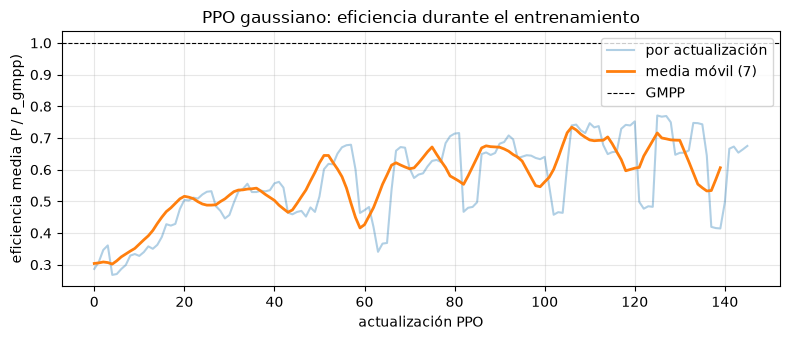

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(train_curve, alpha=0.35, label="por actualización")
w = max(1, len(train_curve) // 20)
ax.plot(np.convolve(train_curve, np.ones(w) / w, mode="valid"), lw=2, label=f"media móvil ({w})")
ax.axhline(1.0, color="k", ls="--", lw=0.8, label="GMPP")
ax.set_xlabel("actualización PPO")
ax.set_ylabel("eficiencia media (P / P_gmpp)")
ax.set_title("PPO gaussiano: eficiencia durante el entrenamiento")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Evaluación determinista

Se usa la media `mu(s)` de la política (sin ruido), igual que una política desplegada.

In [13]:
@torch.no_grad()
def run_policy(policy, env, **reset_kw):
    obs, info = env.reset(**reset_kw)
    effs, powers = [], []
    while True:
        mu = policy.actor(torch.as_tensor(obs, dtype=torch.float32, device=device)).cpu().numpy()
        obs, _, _, trunc, info = env.step(np.clip(mu, 0.0, 1.0))
        effs.append(info["efficiency"])
        powers.append(info["p_pv"])
        if trunc:
            return float(np.mean(effs)), np.array(powers)


dyn = PVMPPTEnv(files, switch_every=2000, max_steps=4000)
combos = dyn.paper_combinations(len(files))

rows = []
for ab in combos:
    eta_ppo, p_ppo = run_policy(policy, dyn, options={"sequence": list(ab)})
    eta_base = scan_and_hold(dyn, options={"sequence": list(ab)})
    rows.append((ab, eta_ppo, eta_base))

print(f"{'combinación':<18}{'PPO':>8}{'scan&hold':>12}")
for (a, b), ep, eb in rows:
    print(f"caso_{a} -> caso_{b}   {ep:8.3f}{eb:12.3f}")
print(f"{'promedio':<18}{np.mean([r[1] for r in rows]):8.3f}{np.mean([r[2] for r in rows]):12.3f}")

# Comparación estática por caso (sin cambios de sombra)
static = PVMPPTEnv(files)
print("\nEstático por caso (PPO):")
for k, c in enumerate(static.curves):
    eta, _ = run_policy(policy, static, options={"case": k})
    print(f"  {c.name}: eta = {eta:.3f}")

combinación            PPO   scan&hold
caso_0 -> caso_1      0.898       0.892
caso_0 -> caso_2      0.698       0.855
caso_0 -> caso_3      0.840       0.900
caso_1 -> caso_0      0.898       0.892
caso_1 -> caso_2      0.751       0.866
caso_1 -> caso_3      0.893       0.911
caso_2 -> caso_0      0.698       0.855
caso_2 -> caso_1      0.751       0.866
caso_2 -> caso_3      0.693       0.750
caso_3 -> caso_0      0.839       0.900
caso_3 -> caso_1      0.893       0.911
caso_3 -> caso_2      0.693       0.874
promedio             0.795       0.873

Estático por caso (PPO):
  caso_0: eta = 0.844
  caso_1: eta = 0.951
  caso_2: eta = 0.552
  caso_3: eta = 0.835


## 8. Trayectoria de potencia en una combinación

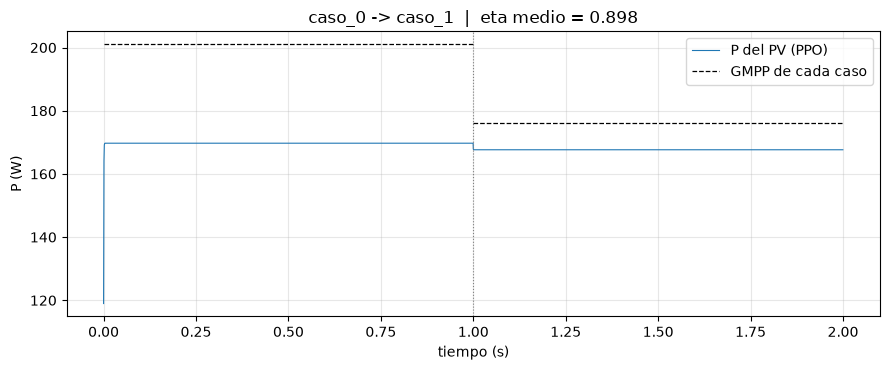

In [14]:
ab = (0, 1)
eta, p = run_policy(policy, dyn, options={"sequence": list(ab)})
gm0, gm1 = dyn.curves[ab[0]].p_gmpp, dyn.curves[ab[1]].p_gmpp

fig, ax = plt.subplots(figsize=(9, 3.8))
t = np.arange(len(p)) * dyn.waiting_time
ax.plot(t, p, lw=0.8, label="P del PV (PPO)")
ax.hlines([gm0, gm1], [0, 1], [1, 2], colors="k", linestyles="--", lw=0.9, label="GMPP de cada caso")
ax.axvline(1.0, color="gray", ls=":", lw=0.8)
ax.set_xlabel("tiempo (s)"); ax.set_ylabel("P (W)")
ax.set_title(f"caso_{ab[0]} -> caso_{ab[1]}  |  eta medio = {eta:.3f}")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 9. Guardar el modelo

In [15]:
torch.save({"state_dict": policy.state_dict(), "hidden": CFG["hidden"], "cfg": CFG},"ppo_pv_mppt.pt")
print("guardado: ppo_pv_mppt.pt")

guardado: ppo_pv_mppt.pt


## 10. Barrido para buscar mejores hiperparámetros

In [16]:
import random
import pandas as pd

# ---------------------------------------------------------------
# Barrido aleatorio de hiperparámetros para PPO gaussiano
# ---------------------------------------------------------------
SEARCH_SPACE = {
    "lr":        [1e-4, 3e-4, 1e-3],
    "n_steps":   [256, 512, 1024],
    "n_epochs":  [5, 10, 20],
    "minibatch": [128, 256, 512],
    "clip":      [0.1, 0.2, 0.3],
    "ent_coef":  [0.0, 1e-3, 1e-2],
    "gamma":     [0.95, 0.99, 0.995],
    "lam":       [0.90, 0.95, 0.99],
    "hidden":    [(64, 64), (128, 128)],
}
N_TRIALS = 24          # configuraciones aleatorias a probar
SEEDS = [0, 1]         # semillas por configuración (promedio + desviación)
TOTAL_TIMESTEPS = 300_000   # presupuesto de búsqueda (corto, para comparar rápido)
FINAL_TIMESTEPS = 1_000_000 # presupuesto para reentrenar la mejor configuración
FINAL_SEEDS = [0, 1, 2]

rng = random.Random(SEED)


def sample_cfg():
    cfg = dict(CFG)
    for k, vals in SEARCH_SPACE.items():
        cfg[k] = rng.choice(vals)
    cfg["total_timesteps"] = TOTAL_TIMESTEPS
    return cfg


def evaluate(policy):
    """Eficiencia media y mínima sobre las 12 combinaciones de la Fig. 14 (política determinista)."""
    etas = []
    for ab in dyn.paper_combinations(len(files)):
        eta, _ = run_policy(policy, dyn, options={"sequence": list(ab)})
        etas.append(eta)
    return float(np.mean(etas)), float(np.min(etas))


# Línea base para comparar
baseline = float(np.mean([
    scan_and_hold(dyn, options={"sequence": list(ab)}) for ab in dyn.paper_combinations(len(files))
]))
print(f"Línea base scan&hold (promedio 12 combinaciones): {baseline:.3f}\n")

# ---------------------------------------------------------------
# Barrido
# ---------------------------------------------------------------
rows = []
for trial in range(N_TRIALS):
    cfg = sample_cfg()
    means, mins = [], []
    for seed in SEEDS:
        policy, _, _ = train_ppo(cfg, seed=seed, verbose_every=10**9)
        m, mn = evaluate(policy)
        means.append(m)
        mins.append(mn)

    row = {k: (str(cfg[k]) if isinstance(cfg[k], tuple) else cfg[k]) for k in SEARCH_SPACE}
    row.update(score_mean=np.mean(means), score_std=np.std(means), score_min=np.mean(mins))
    rows.append(row)
    print(f"[{trial+1:2d}/{N_TRIALS}] score={row['score_mean']:.3f} ± {row['score_std']:.3f} "
          f"| lr={cfg['lr']} steps={cfg['n_steps']} ep={cfg['n_epochs']} mb={cfg['minibatch']} "
          f"clip={cfg['clip']} ent={cfg['ent_coef']} g={cfg['gamma']} lam={cfg['lam']} h={cfg['hidden']}")

df = pd.DataFrame(rows).sort_values(["score_mean", "score_std"], ascending=[False, True])
df.to_csv("ppo_sweep_results.csv", index=False)
print("\nTop 5:")
print(df.head(5).to_string(index=False))

best = df.iloc[0]
best_cfg = dict(CFG)
for k in SEARCH_SPACE:
    v = best[k]
    best_cfg[k] = eval(v) if k == "hidden" else (v.item() if hasattr(v, "item") else v)
best_cfg["total_timesteps"] = FINAL_TIMESTEPS
print("\nMejor configuración:", {k: best_cfg[k] for k in SEARCH_SPACE})

# ---------------------------------------------------------------
# Reentrenamiento de la mejor configuración con más pasos y varias semillas
# ---------------------------------------------------------------
final_scores, best_policies = [], []
for seed in FINAL_SEEDS:
    pol, _, _ = train_ppo(best_cfg, seed=seed, verbose_every=50)
    m, mn = evaluate(pol)
    final_scores.append(m)
    best_policies.append((seed, m, pol))
    print(f"seed {seed}: eta medio = {m:.3f} | mínimo = {mn:.3f}")

print(f"\nFinal: {np.mean(final_scores):.3f} ± {np.std(final_scores):.3f}  (scan&hold = {baseline:.3f})")

best_seed, best_m, best_pol = max(best_policies, key=lambda x: x[1])
torch.save({"state_dict": best_pol.state_dict(), "hidden": best_cfg["hidden"], "cfg": best_cfg},
           "ppo_pv_mppt_best.pt")
print(f"Mejor modelo (seed {best_seed}) guardado en ppo_pv_mppt_best.pt")

Línea base scan&hold (promedio 12 combinaciones): 0.873

upd  146/146 | pasos  299008 | eta batch 0.484 | sigma 0.322 |   26.8s
upd  146/146 | pasos  299008 | eta batch 0.461 | sigma 0.316 |   26.8s
[ 1/24] score=0.799 ± 0.002 | lr=0.0003 steps=512 ep=5 mb=256 clip=0.3 ent=0.001 g=0.99 lam=0.95 h=(128, 128)
upd   73/73 | pasos  299008 | eta batch 0.426 | sigma 0.377 |   23.8s
upd   73/73 | pasos  299008 | eta batch 0.402 | sigma 0.379 |   23.8s
[ 2/24] score=0.835 ± 0.014 | lr=0.0003 steps=1024 ep=5 mb=512 clip=0.1 ent=0.001 g=0.95 lam=0.9 h=(128, 128)
upd   73/73 | pasos  299008 | eta batch 0.900 | sigma 0.013 |   68.9s
upd   73/73 | pasos  299008 | eta batch 0.897 | sigma 0.010 |   69.4s
[ 3/24] score=0.917 ± 0.007 | lr=0.001 steps=1024 ep=20 mb=128 clip=0.2 ent=0.0 g=0.995 lam=0.9 h=(128, 128)
upd   73/73 | pasos  299008 | eta batch 0.394 | sigma 0.420 |   26.4s
upd   73/73 | pasos  299008 | eta batch 0.370 | sigma 0.415 |   26.5s
[ 4/24] score=0.801 ± 0.029 | lr=0.0003 steps=1024 e

### Prueba de mejor modelo encontrado

In [17]:
# ---------------------------------------------------------------
# Prueba del mejor modelo del barrido
# ---------------------------------------------------------------
def load_policy(path):
    ck = torch.load(path, map_location=device, weights_only=False)
    pol = GaussianPolicy(5, 1, ck["hidden"]).to(device)
    pol.load_state_dict(ck["state_dict"])
    pol.eval()
    return pol

best_pol = load_policy("ppo_pv_mppt_best.pt")
old_pol = load_policy("ppo_pv_mppt.pt")   # modelo de 300k pasos, para comparar

# (a) Mismas 12 combinaciones usadas en el barrido (sesgado, solo referencia)
dyn = PVMPPTEnv(files, switch_every=2000, max_steps=4000)
seqs_seen = [list(ab) for ab in dyn.paper_combinations(len(files))]

# (b) Conjunto de prueba: no se usó para elegir el modelo
#     cambios cada 1500 pasos, tres segmentos por episodio, secuencias distintas
dyn_test = PVMPPTEnv(files, switch_every=1500, max_steps=4500)
seqs_test = [[0, 2, 1], [3, 2, 0], [1, 3, 2], [2, 0, 3], [0, 3, 2], [1, 2, 0]]

def evaluate_set(pol, env, seqs):
    return [run_policy(pol, env, options={"sequence": s})[0] for s in seqs]

rows = []
for name, env, seqs in [("visto", dyn, seqs_seen), ("prueba", dyn_test, seqs_test)]:
    e_best = evaluate_set(best_pol, env, seqs)
    e_old = evaluate_set(old_pol, env, seqs)
    e_base = [scan_and_hold(env, options={"sequence": s}) for s in seqs]
    rows.append((name, np.mean(e_best), np.mean(e_old), np.mean(e_base)))

print(f"{'conjunto':<10}{'mejor barrido':>16}{'PPO 300k':>12}{'scan&hold':>12}")
for name, b, o, s in rows:
    print(f"{name:<10}{b:16.3f}{o:12.3f}{s:12.3f}")

# Estático por caso para el mejor modelo
static = PVMPPTEnv(files)
print("\nEstático por caso (mejor barrido):")
for k, c in enumerate(static.curves):
    eta, _ = run_policy(best_pol, static, options={"case": k})
    print(f"  {c.name}: eta = {eta:.3f}")

conjunto     mejor barrido    PPO 300k   scan&hold
visto                0.704       0.795       0.873
prueba               0.638       0.763       0.834

Estático por caso (mejor barrido):
  caso_0: eta = 0.774
  caso_1: eta = 0.523
  caso_2: eta = 0.498
  caso_3: eta = 0.958


## 10. Conclusiones


1. Entorno y línea base. Se construyó un entorno Gymnasium para MPPT bajo sombreado parcial, que modela el lazo ST-SMC y el panel con curvas I-V tabuladas de cuatro casos. Se implementó scan_and_hold como referencia sin RL, que replica la estrategia de barrido y reinicio del paper. Esta línea base es fuerte: alcanza una eficiencia media de 0.873 en las 12 combinaciones de la Fig. 14 del paper

2. PPO con política gaussiana. Se implementó PPO con actor gaussiano, crítico, GAE, objetivo clipped y bootstrap en truncamiento. El agente funciona de extremo a extremo y aprende: la eficiencia batch sube de unos 0.32 a cerca de 0.7 durante el entrenamiento. No obstante, no supera a la línea base en ninguna de las configuraciones probadas.

3. Resultados comparados.

| Modelo                 | Conjunto visto | Conjunto de prueba |
|------------------------|----------------|--------------------|
| scan & hold            | 0.873          | 0.834              |
| PPO 300k (inicial)     | 0.795          | 0.763              |
| Mejor del barrido (1M) | 0.704          | 0.638              |

PPO queda entre 8 y 12 puntos por debajo de la línea base. Los resultados por caso muestran que el caso 2 es el más difícil: con PPO se queda en 0.55 o menos, mientras scan & hold lo resuelve con buena precisión. El modelo del barrido también degrada los casos 1 y 2.

4. Barrido de hiperparámetros. El barrido no mejoró el resultado. Cada configuración se evaluó con solo dos semillas, así que la diferencia entre configuraciones probablemente está dentro del ruido de entrenamiento. Además, el mejor modelo se eligió con el mismo conjunto de combinaciones que luego se usó para medirlo, lo que sesga la comparación. La conclusión sobre el barrido es que, con este presupuesto y esta muestra de semillas, no se pudo distinguir una configuración mejor de otra.

5. Limitaciones.

- Los experimentos usan una sola combinación de hiperparámetros y pocas semillas.
- El modelo del panel es tabulado y no incluye dinámica del panel ni del convertidor.
- El ST-SMC se modela como un seguimiento ideal de la referencia, sin su dinámica real.
- El conjunto de prueba es pequeño (6 secuencias).

6. Mejoras.

- Probar action_mode="incremental", que se parece más a P&O.
- Activar smooth_penalty para reducir cambios bruscos de referencia.
- Repetir las comparaciones con 3 o más semillas y reportar media y desviación.
- Evaluar sobre un conjunto de prueba más amplio, con otros intervalos de cambio y otras secuencias.
- Revisar la normalización de la observación para que el caso 2 tenga una señal útil.